# Who should the bank call? Targeting a term-deposit campaign

A Portuguese bank ran phone campaigns to sell term deposits. Out of 45,211 calls,
11.7% ended in a sign-up, so roughly 8 out of 9 calls were wasted.

**Business question:** if the bank can only afford to call part of its list next time,
who should it call first, and how many sign-ups would it keep?

**Data:** UCI Bank Marketing dataset (Moro, Cortez and Rita, 2014), `bank-full.csv`,
May 2008 to November 2010.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#b4b2a9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#d3d1c7", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "text.color": "#0b0b0b",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ecebe6", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 12,
    "axes.titleweight": "medium", "axes.titlelocation": "left",
})

df = pd.read_csv("data/bank-full.csv", sep=";")
df["subscribed"] = (df.y == "yes").astype(int)
print(df.shape)
print(f"Overall conversion: {df.subscribed.mean():.1%}")

(45211, 18)
Overall conversion: 11.7%


## 1. What the data looks like

One row per customer contacted in the campaign. A few columns need care before any modelling:

- `duration` (call length) is only known after the call ends. A model that uses it looks
  brilliant on paper and is useless for deciding who to call. **Dropped.**
- `campaign` (calls made to this person in this campaign) and `day`/`month` describe how the
  bank ran the campaign, not who the customer is. They can't be known for a fresh call list.
  **Kept out of the model**, but studied separately below because they say something useful
  about how to run the next campaign.
- `pdays = -1` means "never contacted before". It is a code, not a number, so I turn it into
  a flag.

In [2]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y,subscribed
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no,0
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no,0
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no,0
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no,0


In [3]:
def rate_by(col, order=None):
    t = df.groupby(col).agg(customers=("subscribed", "size"), conversion=("subscribed", "mean"))
    return t.loc[order] if order else t.sort_values("conversion")

rate_by("poutcome").style.format({"conversion": "{:.1%}", "customers": "{:,}"})

,customers,conversion
poutcome,,
unknown,"36,959",9.2%
failure,"4,901",12.6%
other,"1,840",16.7%
success,"1,511",64.7%


Customers who said yes to a **previous** campaign convert at 65%, more than five times the
average. They are only 3% of the list, so they can't carry the campaign alone, but they
should always be called first.

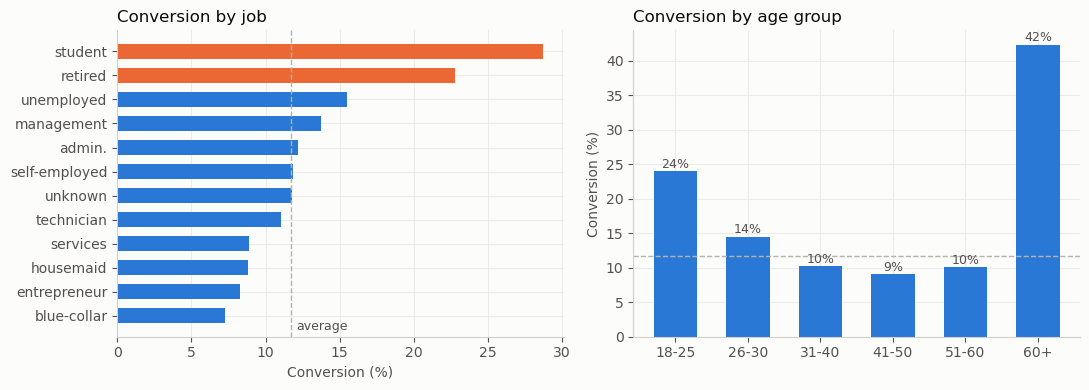

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

job = rate_by("job")
colors = [ORANGE if j in ("student", "retired") else BLUE for j in job.index]
axes[0].barh(job.index, job.conversion * 100, color=colors, height=0.6)
axes[0].axvline(df.subscribed.mean() * 100, color=GREY, ls="--", lw=1)
axes[0].set_title("Conversion by job")
axes[0].set_xlabel("Conversion (%)")
axes[0].text(df.subscribed.mean() * 100 + 0.4, -0.6, "average", color="#52514e", fontsize=9)

bins = pd.cut(df.age, [17, 25, 30, 40, 50, 60, 100],
              labels=["18-25", "26-30", "31-40", "41-50", "51-60", "60+"])
age = df.groupby(bins, observed=True).subscribed.mean() * 100
axes[1].bar(age.index.astype(str), age.values, color=BLUE, width=0.6)
axes[1].axhline(df.subscribed.mean() * 100, color=GREY, ls="--", lw=1)
axes[1].set_title("Conversion by age group")
axes[1].set_ylabel("Conversion (%)")
for i, v in enumerate(age.values):
    axes[1].text(i, v + 0.5, f"{v:.0f}%", ha="center", fontsize=9, color="#52514e")
plt.tight_layout()
plt.savefig("charts/conversion_by_segment.png", dpi=160)
plt.show()

The pattern is a U-shape on age: the young (mostly students) and the over-60s (mostly
retired) are the most likely to say yes. The 31 to 50 band, where most of the calls went,
is the least likely.

## 2. How the campaign was run: the cost of calling again and again

In [5]:
calls = pd.cut(df.campaign, [0, 1, 2, 3, 4, 5, 7, 10, 100],
               labels=["1", "2", "3", "4", "5", "6-7", "8-10", "11+"])
by_calls = df.groupby(calls, observed=True).agg(
    customers=("subscribed", "size"), conversion=("subscribed", "mean"))
by_calls["share_of_calls"] = (by_calls.customers * df.groupby(calls, observed=True).campaign.mean()) \
    / df.campaign.sum()
by_calls.style.format({"conversion": "{:.1%}", "share_of_calls": "{:.1%}", "customers": "{:,}"})

,customers,conversion,share_of_calls
campaign,,,
1,"17,544",14.6%,14.0%
2,"12,505",11.2%,20.0%
3,"5,521",11.2%,13.3%
4,"3,522",9.0%,11.3%
5,"1,764",7.9%,7.1%
6-7,"2,026",6.9%,10.3%
8-10,"1,133",5.9%,7.9%
11+,"1,196",3.9%,16.1%


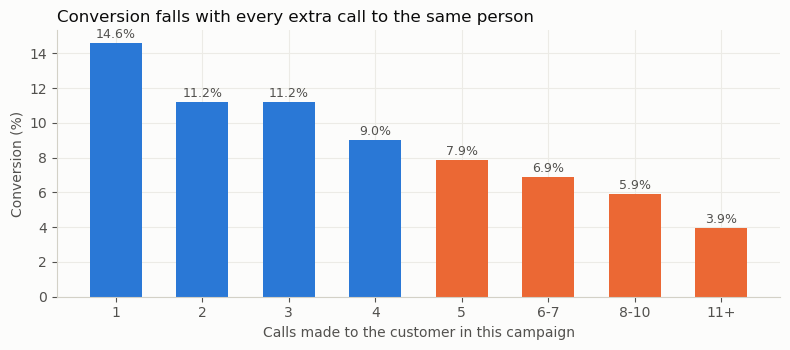

Customers called 5+ times: 13.5% of customers, 41.4% of all calls, 7.4% of sign-ups


In [6]:
fig, ax = plt.subplots(figsize=(8, 3.6))
colors = [ORANGE if i >= 4 else BLUE for i in range(len(by_calls))]
ax.bar(by_calls.index.astype(str), by_calls.conversion * 100, color=colors, width=0.6)
ax.set_title("Conversion falls with every extra call to the same person")
ax.set_xlabel("Calls made to the customer in this campaign")
ax.set_ylabel("Conversion (%)")
for i, v in enumerate(by_calls.conversion * 100):
    ax.text(i, v + 0.3, f"{v:.1f}%", ha="center", fontsize=9, color="#52514e")
plt.tight_layout()
plt.savefig("charts/conversion_by_calls.png", dpi=160)
plt.show()

heavy = df.campaign > 4
print(f"Customers called 5+ times: {heavy.mean():.1%} of customers, "
      f"{df.loc[heavy, 'campaign'].sum() / df.campaign.sum():.1%} of all calls, "
      f"{df.loc[heavy, 'subscribed'].sum() / df.subscribed.sum():.1%} of sign-ups")

A large share of the call effort went to people who had already been called four times.
A simple rule, **stop after four calls**, frees that effort for fresh, better-targeted
customers. This is correlation, not proof: people who need many calls may simply be harder
to reach. It's still the cheapest test the bank could run.

## 3. Scoring customers before the call

Features are only things the bank knows **before** dialling: age, job, marital status,
education, credit default, balance, housing and personal loans, contact channel on file,
and previous campaign history.

I compare two models:

- **Logistic regression**: simple, explainable, and every coefficient can be read as
  an odds ratio a marketing manager can follow.
- **Gradient boosting**: usually more accurate on tabular data, used here as a check on how
  much accuracy the simple model gives up.

25% of customers are held back as a test set and never touched until the end. Models are
compared with 5-fold cross-validation on the remaining 75%.

In [7]:
df["contacted_before"] = (df.pdays != -1).astype(int)
df["days_since_last_contact"] = df.pdays.where(df.pdays != -1, 999)
df["log_balance"] = np.sign(df.balance) * np.log1p(df.balance.abs())

categorical = ["job", "marital", "education", "default", "housing", "loan", "contact", "poutcome"]
numeric = ["age", "log_balance", "previous", "contacted_before", "days_since_last_contact"]

X, y = df[categorical + numeric], df.subscribed
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)

prep = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), categorical),
    ("num", StandardScaler(), numeric),
])
models = {
    "Logistic regression": Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=2000, C=0.5))]),
    "Gradient boosting": Pipeline([("prep", prep), ("model", HistGradientBoostingClassifier(
        max_depth=4, learning_rate=0.05, max_iter=300, random_state=42))]),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc")
    print(f"{name:22s} ROC AUC {scores.mean():.3f} (+/- {scores.std():.3f})")

Logistic regression    ROC AUC 0.739 (+/- 0.005)


Gradient boosting      ROC AUC 0.753 (+/- 0.006)


ROC AUC measures how well a model ranks buyers above non-buyers: 0.5 is a coin flip,
1.0 is perfect. Both models land in the same range, so the explainable one costs
very little. I go with logistic regression and check it once on the untouched test set.

In [8]:
final = models["Logistic regression"].fit(X_train, y_train)
test_scores = final.predict_proba(X_test)[:, 1]
print(f"Test ROC AUC: {roc_auc_score(y_test, test_scores):.3f}")

Test ROC AUC: 0.747


## 4. Turning scores into a call plan: the gains table

Sort the test customers from highest score to lowest and cut them into ten equal groups
(deciles). If the model is useful, the top deciles should hold far more sign-ups than
the bottom ones.

In [9]:
gains = pd.DataFrame({"score": test_scores, "subscribed": y_test.values})
gains["decile"] = pd.qcut(gains.score.rank(method="first", ascending=False), 10, labels=range(1, 11))
table = gains.groupby("decile", observed=True).agg(
    customers=("subscribed", "size"), signups=("subscribed", "sum"))
table["conversion"] = table.signups / table.customers
table["lift"] = table.conversion / gains.subscribed.mean()
table["cum_share_of_list"] = table.customers.cumsum() / table.customers.sum()
table["cum_share_of_signups"] = table.signups.cumsum() / table.signups.sum()
table.style.format({"conversion": "{:.1%}", "lift": "{:.1f}x",
                    "cum_share_of_list": "{:.0%}", "cum_share_of_signups": "{:.0%}"})

,customers,signups,conversion,lift,cum_share_of_list,cum_share_of_signups
decile,,,,,,
1,1131,477,42.2%,3.6x,10%,36%
2,1130,194,17.2%,1.5x,20%,51%
3,1130,151,13.4%,1.1x,30%,62%
4,1130,119,10.5%,0.9x,40%,71%
5,1131,97,8.6%,0.7x,50%,79%
6,1130,77,6.8%,0.6x,60%,84%
7,1130,55,4.9%,0.4x,70%,89%
8,1130,69,6.1%,0.5x,80%,94%
9,1130,49,4.3%,0.4x,90%,97%


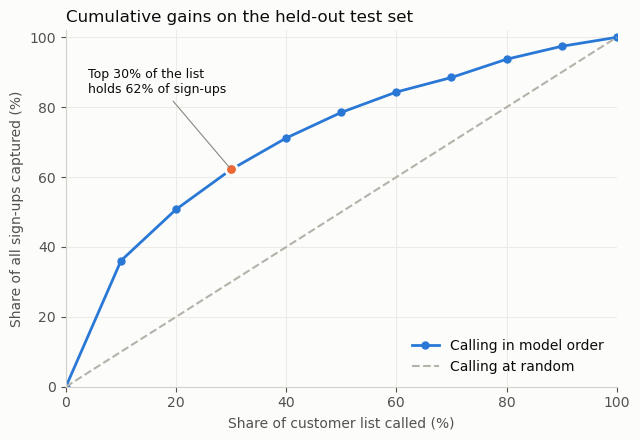

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
x = np.r_[0, table.cum_share_of_list.values] * 100
yv = np.r_[0, table.cum_share_of_signups.values] * 100
ax.plot(x, yv, color=BLUE, lw=2, marker="o", ms=5, label="Calling in model order")
ax.plot([0, 100], [0, 100], color=GREY, lw=1.5, ls="--", label="Calling at random")
top3 = table.cum_share_of_signups.iloc[2] * 100
ax.scatter([30], [top3], s=70, color=ORANGE, zorder=3, edgecolor="#fcfcfb", linewidth=2)
ax.annotate(f"Top 30% of the list\nholds {top3:.0f}% of sign-ups", (30, top3),
            xytext=(4, 84), fontsize=9, color="#0b0b0b",
            arrowprops=dict(arrowstyle="-", color="#888780", lw=0.8))
ax.set_xlabel("Share of customer list called (%)")
ax.set_ylabel("Share of all sign-ups captured (%)")
ax.set_title("Cumulative gains on the held-out test set")
ax.set_xlim(0, 100); ax.set_ylim(0, 102)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.savefig("charts/gains_curve.png", dpi=160)
plt.show()

## 5. What drives the score

Odds ratios from the logistic regression: above 1 pushes the score up, below 1 pulls it
down, holding everything else equal. Every category has its own column and the model is
lightly regularised, so read these as direction and relative strength, not exact multipliers.

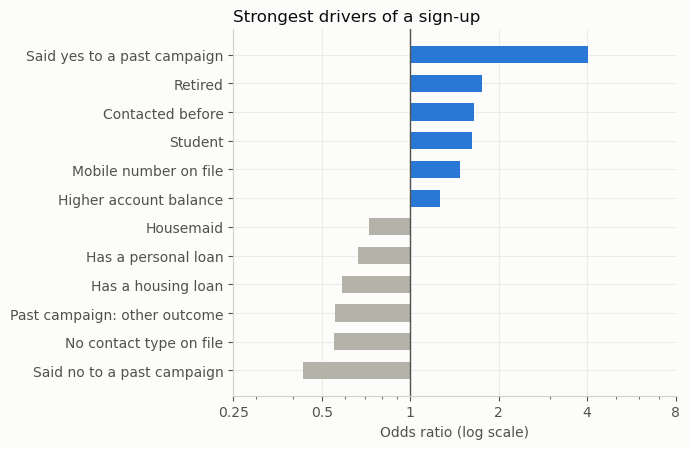

Said no to a past campaign      0.43
No contact type on file         0.55
Past campaign: other outcome    0.56
Has a housing loan              0.59
Has a personal loan             0.67
Housemaid                       0.72
Higher account balance          1.26
Mobile number on file           1.48
Student                         1.63
Contacted before                1.65
Retired                         1.76
Said yes to a past campaign     4.04
dtype: float64

In [11]:
names = final.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(final.named_steps["model"].coef_[0], index=names)
odds = np.exp(coefs).rename(lambda s: s.replace("cat__", "").replace("num__", ""))
top = pd.concat([odds.sort_values().head(6), odds.sort_values().tail(6)])
labels = {
    "poutcome_success": "Said yes to a past campaign", "job_retired": "Retired",
    "contacted_before": "Contacted before", "job_student": "Student",
    "contact_cellular": "Mobile number on file", "log_balance": "Higher account balance",
    "job_housemaid": "Housemaid", "loan_yes": "Has a personal loan",
    "housing_yes": "Has a housing loan", "poutcome_other": "Past campaign: other outcome",
    "contact_unknown": "No contact type on file", "poutcome_failure": "Said no to a past campaign",
    "job_blue-collar": "Blue-collar job", "marital_married": "Married",
}
top.index = [labels.get(i, i) for i in top.index]

fig, ax = plt.subplots(figsize=(7, 4.6))
colors = [BLUE if v > 1 else GREY for v in top.values]
ax.barh(top.index, top.values - 1, left=1, color=colors, height=0.6)
ax.axvline(1, color="#52514e", lw=1)
ax.set_xscale("log")
ax.set_xticks([0.25, 0.5, 1, 2, 4, 8])
ax.set_xticklabels(["0.25", "0.5", "1", "2", "4", "8"])
ax.set_xlabel("Odds ratio (log scale)")
ax.set_title("Strongest drivers of a sign-up")
plt.tight_layout()
plt.savefig("charts/drivers.png", dpi=160)
plt.show()
top.round(2)

## 6. What it's worth: a simple cost model

The dataset has no cost or revenue figures, so these are **assumptions**, stated up front
and easy to change: one call costs EUR 5 in agent time, and one new term deposit is worth
EUR 80 in margin to the bank.

In [12]:
COST_PER_CALL, VALUE_PER_SIGNUP = 5, 80

def plan(share):
    called = gains.sort_values("score", ascending=False).head(int(len(gains) * share))
    signups = called.subscribed.sum()
    return pd.Series({
        "customers_called": len(called),
        "signups": signups,
        "share_of_all_signups": signups / gains.subscribed.sum(),
        "cost_per_signup": len(called) * COST_PER_CALL / signups,
        "profit": signups * VALUE_PER_SIGNUP - len(called) * COST_PER_CALL,
    })

plans = pd.DataFrame({f"Call top {int(s * 100)}%": plan(s) for s in [0.2, 0.3, 0.4, 0.5, 1.0]}).T
plans.rename(index={"Call top 100%": "Call everyone (today)"}) \
     .style.format({"customers_called": "{:,.0f}", "signups": "{:,.0f}",
                    "share_of_all_signups": "{:.0%}", "cost_per_signup": "EUR {:.0f}",
                    "profit": "EUR {:,.0f}"})

,customers_called,signups,share_of_all_signups,cost_per_signup,profit
Call top 20%,"2,260",671,51%,EUR 17,"EUR 42,380"
Call top 30%,"3,390",822,62%,EUR 21,"EUR 48,810"
Call top 40%,"4,521",941,71%,EUR 24,"EUR 52,675"
Call top 50%,"5,651","1,038",79%,EUR 27,"EUR 54,785"
Call everyone (today),"11,303","1,322",100%,EUR 43,"EUR 49,245"


## 7. Recommendation

1. **Call in score order and stop at the top half of the list.** On the test set that keeps
   79% of sign-ups, cuts cost per sign-up from EUR 43 to EUR 27, and raises profit by about
   11% under the cost assumptions. If the budget is tighter, the top 30% still holds 62% of
   sign-ups at EUR 21 each.
2. **Always call past "yes" customers first.** 65% of them say yes again.
3. **Cap attempts at four calls per person.** Customers called five or more times took 41%
   of all calls and gave 7% of sign-ups. Give that capacity to new, high-score customers.
4. **Run it as a test before rolling it out:** split next campaign's list, call one half
   in score order and the other half the old way, and compare cost per sign-up.

## Limitations

- The data is from 2008 to 2010, during the financial crisis, and from one bank. Conversion
  rates moved a lot over that period, so the model needs retraining on recent data before use.
- Train and test are a random split, not a time split. A stricter check would train on the
  earlier calls and test on the later ones.
- Cost and value figures are assumptions, not data.
- The four-call cap is based on correlation. Only the A/B test in point 4 would prove it.